## 1. Kiểm tra môi tường và dữ liệu

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import os

from pathlib import Path

from collections import Counter
from torchvision.datasets import ImageFolder
from PIL import Image

from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import torch.optim as optim
import torch.nn as nn

In [2]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
Device: cuda


In [3]:

DATASET_ROOT = Path(
    "/kaggle/input/datasets/waseemalastal/the-oxford-flowers-102-dataset/flower_data"
)

TRAIN_DIR = DATASET_ROOT / "train"
VALID_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

import json

with open(DATASET_ROOT / "cat_to_name.json", "r") as f:
    cat_to_name = json.load(f)

print('>>> Đã define các directories:')
print(f"Train data: {TRAIN_DIR}")
print(f"Test data: {TEST_DIR}")
print(f"Val data: {VALID_DIR}")
print(f"Class mapping: {cat_to_name}")

>>> Đã define các directories:
Train data: /kaggle/input/datasets/waseemalastal/the-oxford-flowers-102-dataset/flower_data/train
Test data: /kaggle/input/datasets/waseemalastal/the-oxford-flowers-102-dataset/flower_data/test
Val data: /kaggle/input/datasets/waseemalastal/the-oxford-flowers-102-dataset/flower_data/valid
Class mapping: {'21': 'fire lily', '3': 'canterbury bells', '45': 'bolero deep blue', '1': 'pink primrose', '34': 'mexican aster', '27': 'prince of wales feathers', '7': 'moon orchid', '16': 'globe-flower', '25': 'grape hyacinth', '26': 'corn poppy', '79': 'toad lily', '39': 'siam tulip', '24': 'red ginger', '67': 'spring crocus', '35': 'alpine sea holly', '32': 'garden phlox', '10': 'globe thistle', '6': 'tiger lily', '93': 'ball moss', '33': 'love in the mist', '9': 'monkshood', '102': 'blackberry lily', '14': 'spear thistle', '19': 'balloon flower', '100': 'blanket flower', '13': 'king protea', '49': 'oxeye daisy', '15': 'yellow iris', '61': 'cautleya spicata', '31': 

In [4]:

train_raw = ImageFolder(TRAIN_DIR)
valid_raw = ImageFolder(VALID_DIR)

train_counts = Counter(train_raw.targets)
valid_counts = Counter(valid_raw.targets)


summary = pd.DataFrame({
    "Dataset": ["Train", "Validation"],
    "Total images": [
        len(train_raw),
        len(valid_raw)
    ],
    "Min images/class": [
        min(train_counts.values()),
        min(valid_counts.values())
    ],
    "Max images/class": [
        max(train_counts.values()),
        max(valid_counts.values())
    ],
    "Avg images/class": [
        sum(train_counts.values()) / len(train_counts),
        sum(valid_counts.values()) / len(valid_counts)
    ]
})

print(f"Số lượng lớp: {len(train_raw.classes)}")
display(summary.round(2))

Số lượng lớp: 102


,Dataset,Total images,Min images/class,Max images/class,Avg images/class
0,Train,6552,27,206,64.24
1,Validation,818,1,28,8.02


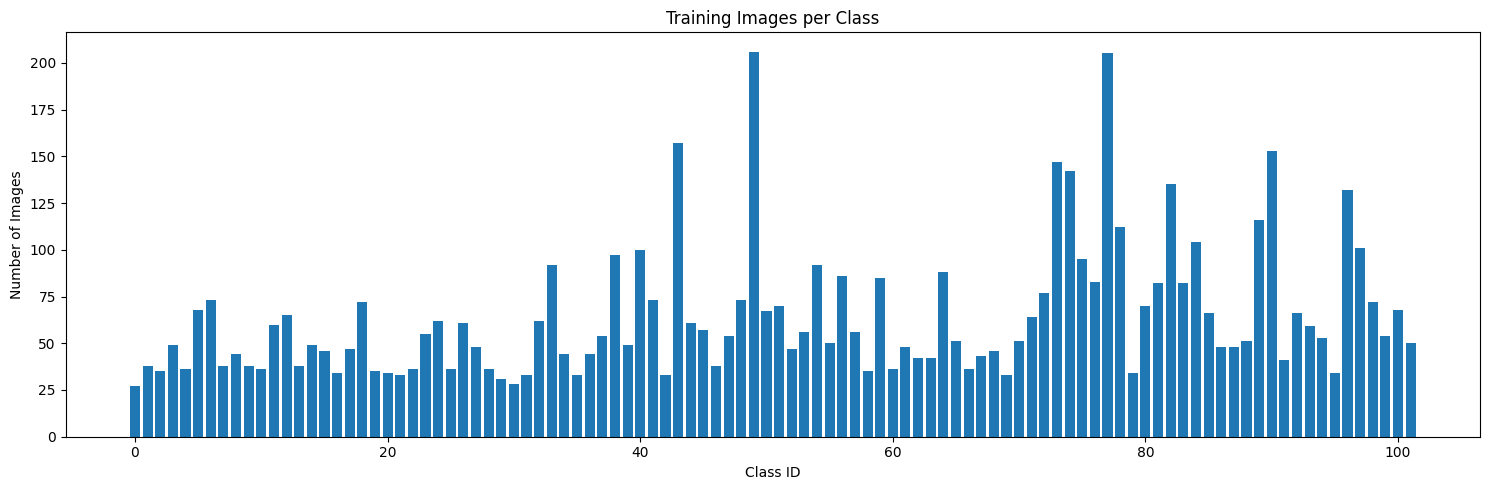

In [5]:
class_ids = range(len(train_counts))
counts = [train_counts[i] for i in class_ids]

plt.figure(figsize=(15, 5))
plt.bar(class_ids, counts)

plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.title("Training Images per Class")

plt.tight_layout()
plt.show()

,Dimension,Min,Max
0,Width,500,1024
1,Height,500,1168


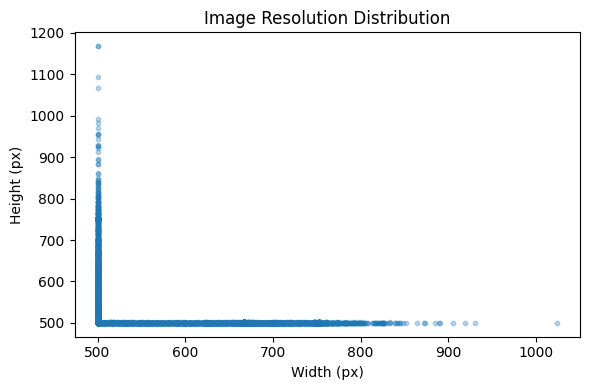

In [66]:

widths = []
heights = []

for image_path, _ in train_raw.samples:
    with Image.open(image_path) as img:
        width, height = img.size
        widths.append(width)
        heights.append(height)

widths = np.array(widths)
heights = np.array(heights)

size_summary = pd.DataFrame({
    "Dimension": ["Width", "Height"],
    "Min": [
        widths.min(),
        heights.min()
    ],
    "Max": [
        widths.max(),
        heights.max()
    ]
})
display(size_summary)

plt.figure(figsize=(6, 4))
plt.scatter(widths, heights, alpha=0.3, s=10)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Image Resolution Distribution")

plt.tight_layout()
plt.show()

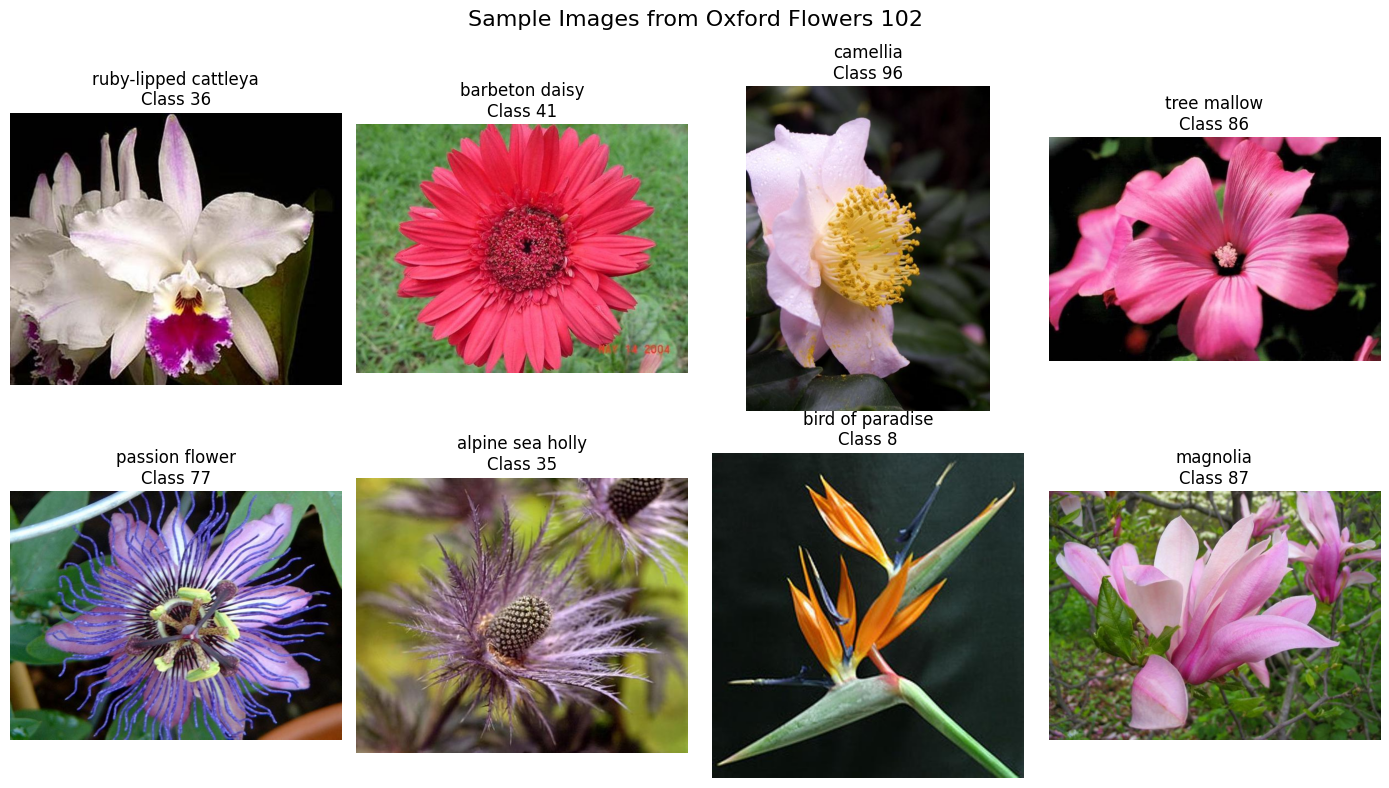

In [7]:
import random

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

indices = random.sample(range(len(train_raw)), 8)

for ax, idx in zip(axes.flat, indices):
    image, label = train_raw[idx]

    class_id = train_raw.classes[label]
    class_name = cat_to_name[class_id]

    ax.imshow(image)
    ax.set_title(f"{class_name}\nClass {class_id}")
    ax.axis("off")

plt.suptitle("Sample Images from Oxford Flowers 102", fontsize=16)
plt.tight_layout()
plt.show()

## 2. Image processing và tăng cường dữ liệu

In [9]:
transforms = torchvision.transforms
IMG_SIZE = 224 # ResNet sử dụng 224 x 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

train_transform_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
])

valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
])

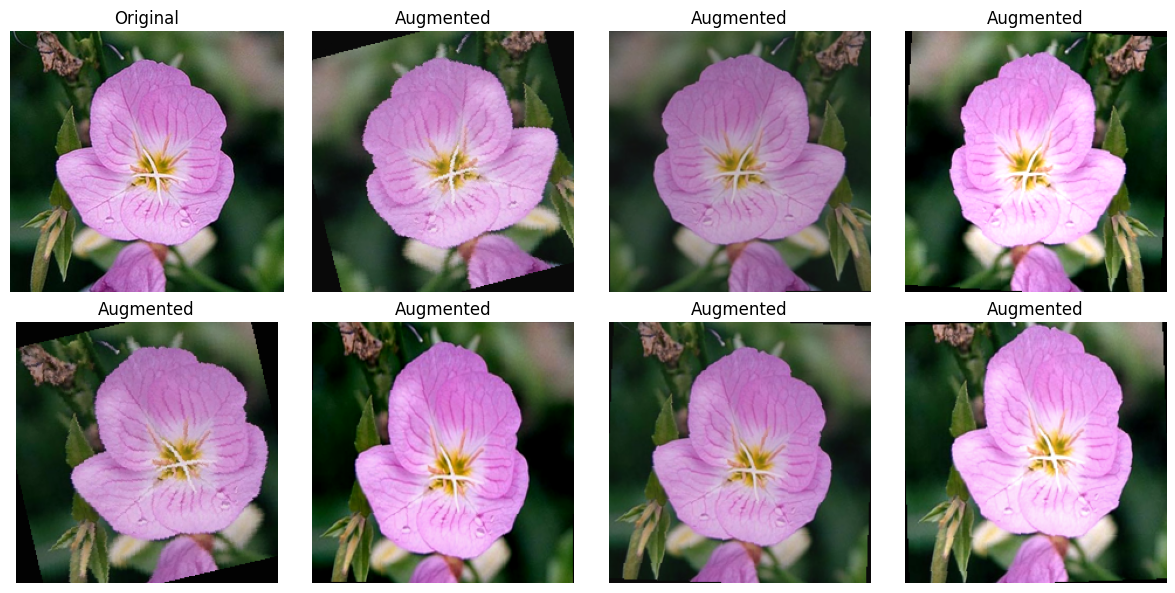

In [10]:
import matplotlib.pyplot as plt

image, label = train_raw[0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for ax in axes.flat[1:]:
    augmented = train_transform_aug(image)

    ax.imshow(augmented.permute(1, 2, 0))
    ax.set_title("Augmented")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Data loader

In [11]:
# Tạo data train (ko tắng cường) và loader
train_dataset_no_aug = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_no_aug
)

train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Tạo data aug và loader
train_dataset_aug = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_aug
)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Tạo data val và loader
valid_dataset = ImageFolder(
    VALID_DIR,
    transform=valid_transform
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Tạo data test và loader để đánh giá cuối cùng
test_dataset = ImageFolder(
    TEST_DIR,
    transform=valid_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


## 4. ResNet setup

In [14]:
class_number = len(train_raw.classes)

def create_model():
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    
    model.fc = nn.Linear(
        model.fc.in_features,
        class_number
    )

    model = model.to(device)   

    return model

## 5. Train và evaluate

In [16]:
def epoch_train(model, loss_function, optimizer, loader, device):
    model.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    # Chạy qua từng batch
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        running_correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = running_correct / total

    return epoch_loss, epoch_accuracy

# for images, labels in train_loader_no_aug:
#     print('>>>', labels, images)

In [18]:
def evaluate(model, loss_function, loader, device):
    model.eval()

    running_loss = 0.0
    running_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_function(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            running_correct += (predictions == labels).sum().item()
            total += labels.size(0)

    loss = running_loss / total
    accuracy = running_correct / total

    return loss, accuracy

In [37]:
def train_model(model, train_loader, val_loader, loss_function, optimizer, device, epochs):
    history = {
            "train_loss": [],
            "train_acc": [],
            "val_loss": [],
            "val_acc": []
        }

    for epoch in range(epochs):
        train_loss, train_acc = epoch_train(
            model = model,
            loss_function = loss_function,
            loader = train_loader,
            optimizer = optimizer,
            device = device
        )

        val_loss, val_acc = evaluate(
            model = model,
            loss_function = loss_function,
            loader = val_loader,
            device = device
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"=== Epoch [{epoch + 1}/{epochs}] ===================")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Train Acc: {train_acc:.2%}")
        print(f"Val Loss: {val_loss:.4f}")
        print(f"Val Acc: {val_acc:.2%}")

    return history

In [38]:
loss_func = nn.CrossEntropyLoss()

EPOCHS = 10
LEARNING_RATE = 1e-4

model_no_aug = create_model()
optimizer = optim.Adam(
    model_no_aug.parameters(),
    lr=LEARNING_RATE
)
print("Đã setup xong loss function và optimizer!")

history_train_no_aug = train_model(
    model=model_no_aug,
    train_loader=train_loader_no_aug,
    val_loader=valid_loader,
    loss_function=loss_func,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)


Đã setup xong loss function và optimizer!
=== Epoch [1/10] ===================
Train Loss: 1.9627
Train Acc: 65.19%
Val Loss: 1.8938
Val Acc: 62.96%
=== Epoch [2/10] ===================
Train Loss: 0.3343
Train Acc: 97.36%
Val Loss: 1.2910
Val Acc: 73.47%
=== Epoch [3/10] ===================
Train Loss: 0.0930
Train Acc: 99.66%
Val Loss: 1.1959
Val Acc: 73.96%
=== Epoch [4/10] ===================
Train Loss: 0.0374
Train Acc: 99.97%
Val Loss: 1.0916
Val Acc: 75.55%
=== Epoch [5/10] ===================
Train Loss: 0.0209
Train Acc: 100.00%
Val Loss: 0.9400
Val Acc: 79.83%
=== Epoch [6/10] ===================
Train Loss: 0.0139
Train Acc: 100.00%
Val Loss: 0.9705
Val Acc: 78.97%
=== Epoch [7/10] ===================
Train Loss: 0.0098
Train Acc: 100.00%
Val Loss: 0.8611
Val Acc: 80.81%
=== Epoch [8/10] ===================
Train Loss: 0.0077
Train Acc: 100.00%
Val Loss: 0.9658
Val Acc: 78.73%
=== Epoch [9/10] ===================
Train Loss: 0.0055
Train Acc: 100.00%
Val Loss: 0.9148
Val Ac

In [39]:
model_aug = create_model()

loss_func_aug = nn.CrossEntropyLoss()

optimizer_aug = optim.Adam(
    model_aug.parameters(),
    lr=1e-4
)

history_train_aug = train_model(
    model=model_aug,
    train_loader=train_loader_aug,
    val_loader=valid_loader,
    loss_function=loss_func_aug,
    optimizer=optimizer_aug,
    device=device,
    epochs=10
)

=== Epoch [1/10] ===================
Train Loss: 2.1387
Train Acc: 59.54%
Val Loss: 0.7359
Val Acc: 89.85%
=== Epoch [2/10] ===================
Train Loss: 0.5115
Train Acc: 93.53%
Val Loss: 0.3268
Val Acc: 95.72%
=== Epoch [3/10] ===================
Train Loss: 0.2130
Train Acc: 97.65%
Val Loss: 0.2182
Val Acc: 96.94%
=== Epoch [4/10] ===================
Train Loss: 0.1080
Train Acc: 99.24%
Val Loss: 0.1711
Val Acc: 96.82%
=== Epoch [5/10] ===================
Train Loss: 0.0694
Train Acc: 99.31%
Val Loss: 0.1547
Val Acc: 97.43%
=== Epoch [6/10] ===================
Train Loss: 0.0442
Train Acc: 99.69%
Val Loss: 0.1509
Val Acc: 96.94%
=== Epoch [7/10] ===================
Train Loss: 0.0298
Train Acc: 99.89%
Val Loss: 0.1186
Val Acc: 98.04%
=== Epoch [8/10] ===================
Train Loss: 0.0192
Train Acc: 99.92%
Val Loss: 0.1152
Val Acc: 97.43%
=== Epoch [9/10] ===================
Train Loss: 0.0283
Train Acc: 99.77%
Val Loss: 0.1282
Val Acc: 97.19%
=== Epoch [10/10] ===================

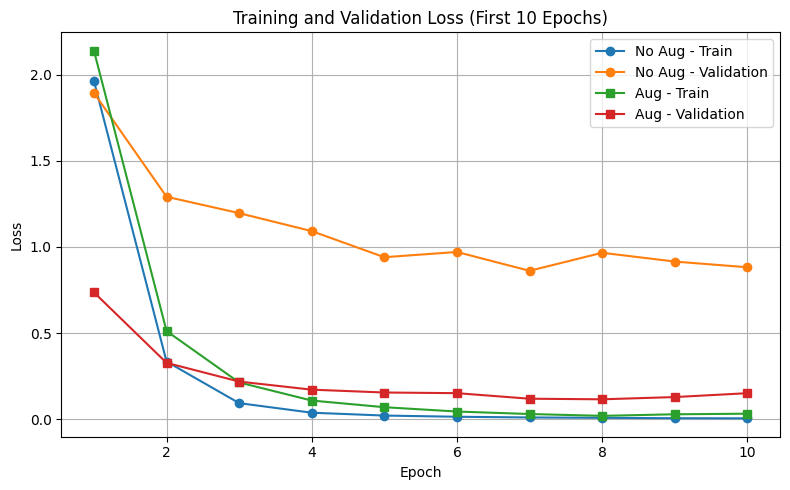

In [40]:
import matplotlib.pyplot as plt

num_epochs = 10
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_train_no_aug["train_loss"][:num_epochs],
    marker="o",
    label="No Aug - Train",
)
plt.plot(
    epochs,
    history_train_no_aug["val_loss"][:num_epochs],
    marker="o",
    label="No Aug - Validation",
)

plt.plot(
    epochs,
    history_train_aug["train_loss"][:num_epochs],
    marker="s",
    label="Aug - Train",
)
plt.plot(
    epochs,
    history_train_aug["val_loss"][:num_epochs],
    marker="s",
    label="Aug - Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss (First 10 Epochs)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

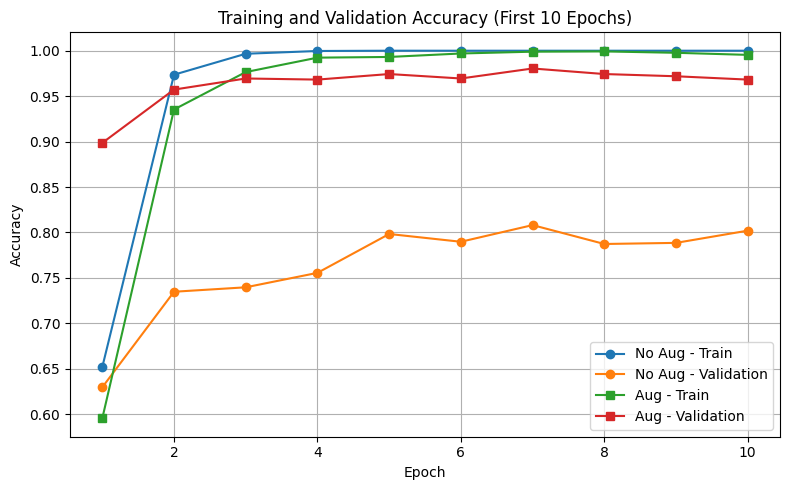

In [41]:
import matplotlib.pyplot as plt

num_epochs = 10
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_train_no_aug["train_acc"][:num_epochs],
    marker="o",
    label="No Aug - Train",
)
plt.plot(
    epochs,
    history_train_no_aug["val_acc"][:num_epochs],
    marker="o",
    label="No Aug - Validation",
)

plt.plot(
    epochs,
    history_train_aug["train_acc"][:num_epochs],
    marker="s",
    label="Aug - Train",
)
plt.plot(
    epochs,
    history_train_aug["val_acc"][:num_epochs],
    marker="s",
    label="Aug - Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy (First 10 Epochs)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

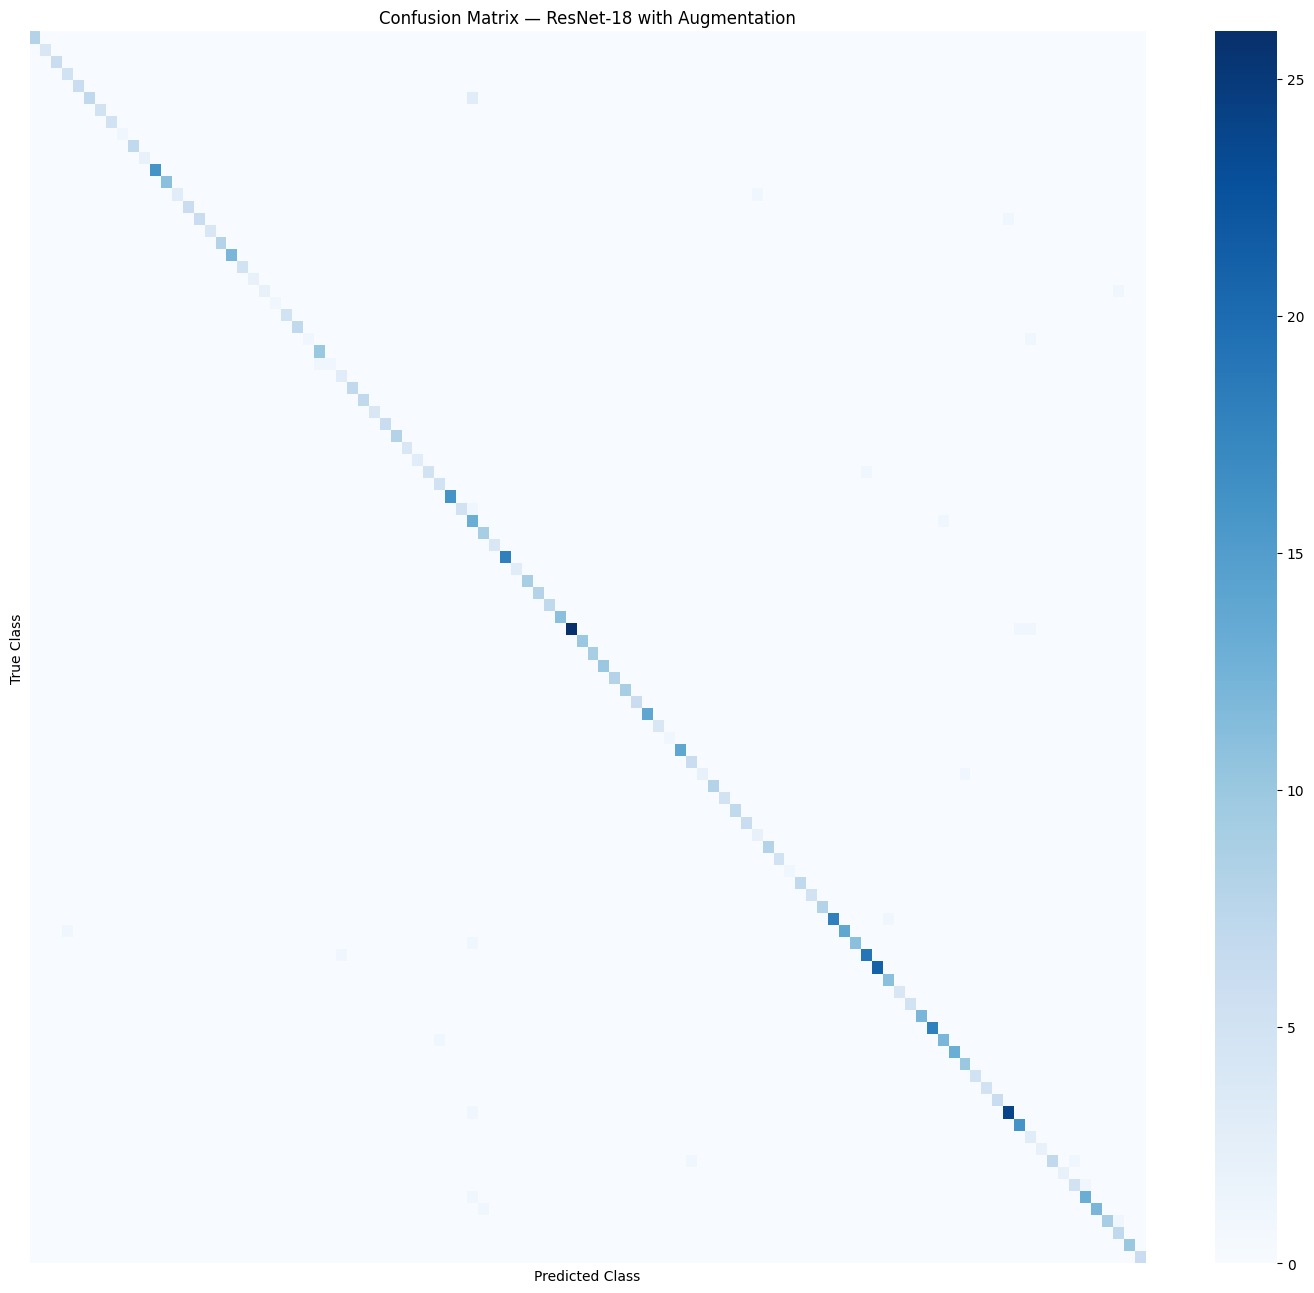

In [49]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

model_aug.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — ResNet-18 with Augmentation")

plt.show()

In [50]:
class_names = test_dataset.classes

confusion_per_class = cm.sum(axis=1) - np.diag(cm)

worst_indices = np.argsort(confusion_per_class)[-10:][::-1]

for idx in worst_indices:
    print(
        f"{idx}: {cat_to_name.get(class_names[idx], class_names[idx])} "
        f"— {confusion_per_class[idx]} misclassified"
    )

5: snapdragon — 3 misclassified
93: hippeastrum — 2 misclassified
49: petunia — 2 misclassified
89: cyclamen — 1 misclassified
96: foxglove — 1 misclassified
97: bougainvillea — 1 misclassified
75: thorn apple — 1 misclassified
74: rose — 1 misclassified
73: water lily — 1 misclassified
83: clematis — 1 misclassified


In [ ]:
import random
import textwrap
import math

NUM_SAMPLES = 6
GREEN, RED = "#2e7d32", "#c62828"

def wrap(name, width=24):
    return "\n".join(textwrap.wrap(name, width))

def collect_predictions(model, loader, device):
    model.eval()
    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels_device = labels.to(device)
            outputs = model(images)
            loss = loss_func(outputs, labels_device)

            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)
            all_labels.extend(labels.numpy())
            all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

    return all_labels, all_predictions, total_loss / total

# Chay model_aug mot lan tren toan bo test, roi dung lai du lieu cho hinh va metric.
all_labels_aug, all_predictions_aug, loss_aug = collect_predictions(
    model_aug, test_loader, device
)
num_samples = min(NUM_SAMPLES, len(test_dataset))
sample_indices = random.sample(range(len(test_dataset)), num_samples)
samples = [test_dataset[i] for i in sample_indices]
predictions = [all_predictions_aug[i] for i in sample_indices]

num_cols = min(3, num_samples)
num_rows = math.ceil(num_samples / num_cols)
fig, axes = plt.subplots(
    num_rows, num_cols, figsize=(5 * num_cols, 6.2 * num_rows),
    squeeze=False, constrained_layout=False
)
fig.patch.set_facecolor("white")
fig.suptitle("Random Test Predictions — ResNet-18 with Augmentation",
             fontsize=18, fontweight="bold", color="#333333", y=0.98)

for ax, (image, label), prediction in zip(axes.flat, samples, predictions):
    true_name = cat_to_name.get(
        str(test_dataset.classes[label]), test_dataset.classes[label]
    )
    pred_name = cat_to_name.get(
        str(test_dataset.classes[prediction]), test_dataset.classes[prediction]
    )
    correct = label == prediction
    color = GREEN if correct else RED

    ax.imshow(image.clamp(0, 1).permute(1, 2, 0))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
    ax.set_title(f"True: {wrap(true_name)}", fontsize=12,
                 fontweight="bold", color=GREEN, pad=12)
    ax.set_xlabel(f"Pred: {wrap(pred_name)}", fontsize=12,
                  fontweight="bold", color=color, labelpad=12)

for ax in axes.flat[num_samples:]:
    ax.set_visible(False)

fig.subplots_adjust(top=0.88, bottom=0.08, hspace=0.48, wspace=0.04)
plt.show()

## 6. So sánh metric giữa hai model

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def calculate_metrics(labels, predictions, loss):
    return {
        "Loss": loss,
        "Accuracy": accuracy_score(labels, predictions),
        "Precision (macro)": precision_score(labels, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(labels, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(labels, predictions, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(labels, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(labels, predictions, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(labels, predictions, average="weighted", zero_division=0),
    }

comparison = pd.DataFrame(
    [
        calculate_metrics(
            *collect_predictions(model_no_aug, test_loader, device)
        ),
        calculate_metrics(all_labels_aug, all_predictions_aug, loss_aug),
    ],
    index=["No Augmentation", "With Augmentation"]
)

display(comparison.style.format({
    "Loss": "{:.4f}",
    "Accuracy": "{:.2%}",
    "Precision (macro)": "{:.2%}",
    "Recall (macro)": "{:.2%}",
    "F1 (macro)": "{:.2%}",
    "Precision (weighted)": "{:.2%}",
    "Recall (weighted)": "{:.2%}",
    "F1 (weighted)": "{:.2%}",
}))